# Brush GPT: Painting Cat Faces Stroke by Stroke with an Autoregressive Transformer

## Abstract

I study an unconditional generation problem: starting from a blank canvas, with no photograph, text or class label
as input, a model paints a cat that does not exist, **one brush stroke at a time**. Its output is not a grid of pixels
but a sequence of interpretable oil-paint strokes, each with an explicit position, orientation, size, colour and
opacity.

To obtain training data, I convert real cat-face photographs into stroke sequences with a differentiable renderer:
every painting consists of exactly 608 strokes laid down in four coarse-to-fine stages. Each stroke is discretised
into five tokens, and a decoder-only Transformer with 27.9 million parameters is trained to predict the next token.
The training set contains 3,413 cats from AFHQ; an experiment in progress adds 6,327 cats from the CAT dataset.

To measure whether the generated faces are structurally correct, I use a cat-face landmark model trained only on
photographs as an **independent judge** of how recognisable the eyes are. Three design choices raise the eye score of
generated paintings from 0.84 to 0.91 of that of real paintings: writing nine facial keypoints first as a
compositional plan, up-weighting the loss on strokes around the eyes, and aligning every face to a canonical
position. Along the same progression, the FID against the training paintings falls from 209 to 182, and no
generated painting is closer to the training set than an unseen real painting is. Against held-out test paintings,
however, the full model reaches an FID of 196, compared with 49 for real paintings: the generated distribution
remains far from the real one.

To locate where the errors arise, I give the model the first *k* stages of a real painting, let it complete the
rest, and compare the result with the same cat's full painting. The eyes are lost mainly in the **two finest stages**,
which are also the stages with the lowest per-token loss. Per-token loss therefore cannot tell where the visible
errors occur; they have to be measured on the rendered painting with a structural judge.

Finally, I am extending the fact that the output is a sequence of strokes to **attribute-controlled painting with
local editing** (work in progress, not yet complete). A user specifies the cat's appearance, for example turning a
black cat into a white cat with heart-shaped patches on its crown, a blue left eye and a green right eye, and the
model paints under that condition. Because the painting process can be watched and every stroke can be edited or
removed on its own, each later change should require repainting only the strokes in the affected region rather
than the whole picture. The attribute definition, the measurement of attributes on photographs, and a reader that
extracts them from coloured doodles are complete; the attribute-conditioned Brush GPT and local repainting have not
yet been implemented.

**Keywords:** stroke-based rendering, autoregressive generation, discrete tokens, Transformer, generative model
evaluation, conditional generation, local editing

**Evidence rule.** Every number in this notebook comes from one of three sources, all listed in Appendix E:
*computed here* (by the code below, from files the experiments saved), *quoted* (copied from a project document
because the raw output was not kept as a file), or *not measured*. The notebook neither trains nor samples any
model; it only reads saved logs and metrics, and decodes and renders saved tokens on the CPU.

In [1]:
import json
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

os.environ["BRUSHGPT_DEVICE"] = "cpu"             # this notebook uses the CPU only
ML = Path.cwd().parent                            # the notebook lives in ml/notebooks
sys.path.insert(0, str(ML))
RUNS = ML / "runs/brushgpt"
NAMES = ["C_overlap_heads", "D_all_cats", "E_points", "F_eye_weight", "G_points_eyes", "H_aligned",
         "I_aligned_points_eyes"]
# descriptive names of the runs (Appendix D maps them to run codes)
LABEL = {"C_overlap_heads": "Small data", "D_all_cats": "Baseline", "E_points": "+Points", "F_eye_weight": "+Eye weight",
         "G_points_eyes": "+Points +eye weight", "H_aligned": "+Aligned", "I_aligned_points_eyes": "Full model"}
plt.rcParams.update({"figure.dpi": 105, "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 9})

USED, VERIFY = [], []                             # every file read; every number with its source (Appendix E)


def need(path):
    path = Path(path)
    USED.append(path)
    return path


def ver(claim, value, source, kind):
    '''Register a number for Appendix E. kind: computed here / quoted / not measured.'''
    VERIFY.append((claim, value, source, kind))
    return value


from sellanything_ml.sketch import brushgpt as G       # decoding and rendering only; no model is built
from sellanything_ml.sketch import brushtokens as T
from sellanything_ml.sketch import catbrush as B

print("loaded; device:", os.environ["BRUSHGPT_DEVICE"])

loaded; device: cpu


## 1. Introduction

### 1.1 Problem

Recent image generators, such as diffusion models and autoregressive pixel models, output a finished raster image.
Human painters do not work this way. An oil painting is built up one stroke at a time: broad strokes lay in blocks of
colour first, and progressively smaller brushes add structure and detail, each stroke with a definite position,
direction, size and colour. If a model's output is itself a sequence of strokes, then (1) the generation *process*
can be watched, (2) every stroke can be edited or removed on its own, and (3) one can ask directly at which stroke,
and in which stage, the model goes wrong.

I study the hardest version of this problem: **unconditional generation**. The model sees no photograph, text or
class label; it starts from a blank canvas, decides every stroke itself, and paints a cat that is not in the training
data. I chose cat faces because they have a clear structure that can be checked objectively (two eyes, a nose, a
mouth and two ears), and because the eyes are both the part most likely to fail and the failure a viewer notices
first.

**Extension: specified appearance and local editing (in progress, not yet complete).** Properties (1) and (2) also
enable a different use. A user can specify the cat's appearance, for example turning a black cat into a white cat
with heart-shaped patches on its crown, a blue left eye and a green right eye, and the model paints it stroke by
stroke under that condition. When the user then changes a single detail, say the right eye from green to blue, only
the strokes in the small region tied to that detail (around the right eye) should need to be regenerated, because
the painting is a sequence of strokes that can each be edited or removed. All other strokes stay as they are, and the
user can watch that small region being repainted. A pixel-based generator would have to regenerate the whole image
for the same change, or rely on a separately trained inpainting mechanism; a stroke sequence naturally decomposes the
picture into units that can be located and replaced. The core of this paper (Sections 3–9) remains unconditional
generation. The definition of appearance attributes and the methods for reading them from photographs and doodles are
complete and reported in Section 11; the attribute-conditioned model and local repainting are not yet implemented,
and Section 11.9 describes the planned approach and how it will be evaluated.

### 1.2 Why it is hard

* **Long sequences.** Every cat is exactly 608 strokes of five tokens each. With the structural markers and face
  points, a painting is 3,064 tokens, so the model makes 3,063 successive predictions, and later strokes inherit
  earlier mistakes.
* **Five heterogeneous fields per stroke.** Position is a geometric quantity, whereas colour is a discrete value among
  6,912 classes; the two differ completely in difficulty and distribution.
* **Ambiguous stroke order.** All strokes within a stage are optimised jointly, so their order in the list carries no
  meaning; yet where two strokes overlap, their order determines the picture.
* **Little data.** Only a few thousand to ten thousand cat faces can be converted into strokes by the same painter,
  far below the scale common in image generation.
* **Structurally correct is not the same as close in pixels.** A painting can have the right overall colours and
  outline while its eyes are a blur; neither the FID nor the loss reveals this.

### 1.3 Research questions and contributions

The paper is organised around five research questions. Each is followed by my answer or contribution and the
sections where it appears.

**RQ1:** If oil-paint strokes are discretised into tokens and a standard decoder-only Transformer predicts them one
token at a time, can it learn to generate paintings that are decodable, look like cats, and do not copy the training
data?
→ I build a complete pipeline from photographs to learnable stroke sequences: landmark labelling, data filtering, a
painter based on differentiable rendering, tokenisation with a fixed layout, and a reordering of strokes that leaves
the picture unchanged (Sections 3 and 4). A model trained on this data generates decodable, cat-like paintings that
do not copy the training data (Sections 6.1 and 6.3).

**RQ2:** Which design choices improve *structure*, with the eyes as its representative?
→ I propose a **structural evaluation** that uses an independent landmark model as the judge and compares data
versions fairly through the ratio of generated to real scores (Section 5.2). I compare a compositional plan (writing
the face points first), an eye-region loss weight and face alignment, alone and combined. The ablations show that the
plan and the eye weight exceed noise only **when combined**, while alignment provides a separate, independent
improvement (Sections 6.1–6.3).

**RQ3:** In coarse-to-fine generation, at which stage do the errors arise, and can the per-token loss answer this
question?
→ I answer with a stage-by-stage error analysis. The model completes real paintings from their first *k* stages, and
each cat is compared with its own real painting. The errors are located mainly in the two finest stages, while the
per-token loss points in the opposite direction (Section 6.5).

**RQ4 (in progress):** Does a fur-flow field derived from an animal's facial keypoints by the rules of fur growth
produce finer strokes that follow the fur better than the original approach, which sets stroke direction from image
edges alone?
→ From the cat's nine facial keypoints I construct a fur-flow field over the whole face according to how fur grows,
use it to constrain the direction of every stroke, and compare it quantitatively with three image-only direction rules
from the literature. To my knowledge, existing methods that set stroke direction from facial landmarks all target
human faces and follow contours and edges (Section 10).

**RQ5 (in progress):** Can the model paint under user-specified appearance attributes and, when the user changes only
one attribute, repaint only the strokes in the relevant small region while leaving the rest of the picture unchanged?
→ I define a set of appearance attributes relative to the cat's face that stay consistent under the left/right
convention and mirroring, measure them on photographs, and train an attribute reader on synthetic doodles drawn from
known attributes. A Brush GPT conditioned on these attributes, local repainting of only the affected region, and an
independent exam set of real doodles are planned (Section 11; the conditional model and local repainting are not yet
implemented).

### 1.4 Organisation

Section 2 reviews related work and positions this paper. Section 3 describes the data and Section 4 the method:
the painter, tokenisation, stroke order, the model and three design choices. Section 5 gives the experimental setup
and evaluation metrics, Section 6 the results, Section 7 a discussion, Section 8 the limitations, and Section 9 the
conclusion and future work. Section 10 presents a prototype painter redesigned around the real oil-painting process
and fur flow, together with the plan for a controlled experiment that changes only the painter (in progress).
Section 11 covers generation conditioned on a doodle's description: the definition and measurement of attributes,
the attribute reader, and the plan for an attribute-conditioned Brush GPT with local repainting (in progress).
Appendix A documents an early version whose samples could not be decoded and its fix, Appendices B and C give painter
details and computational cost, Appendix D maps names to run codes, and Appendix E lists the source of every number.

Figure 1 first places every version of Brush GPT trained so far side by side, in training order. Each row is one
version and shows the first eight samples it drew at temperature 1 with seed 0 during evaluation, without any
selection or filtering. Table 9 in Section 5.1 lists how the versions differ. A version still in training keeps an
empty row, which fills in automatically once its samples are saved; later versions are added below in order.

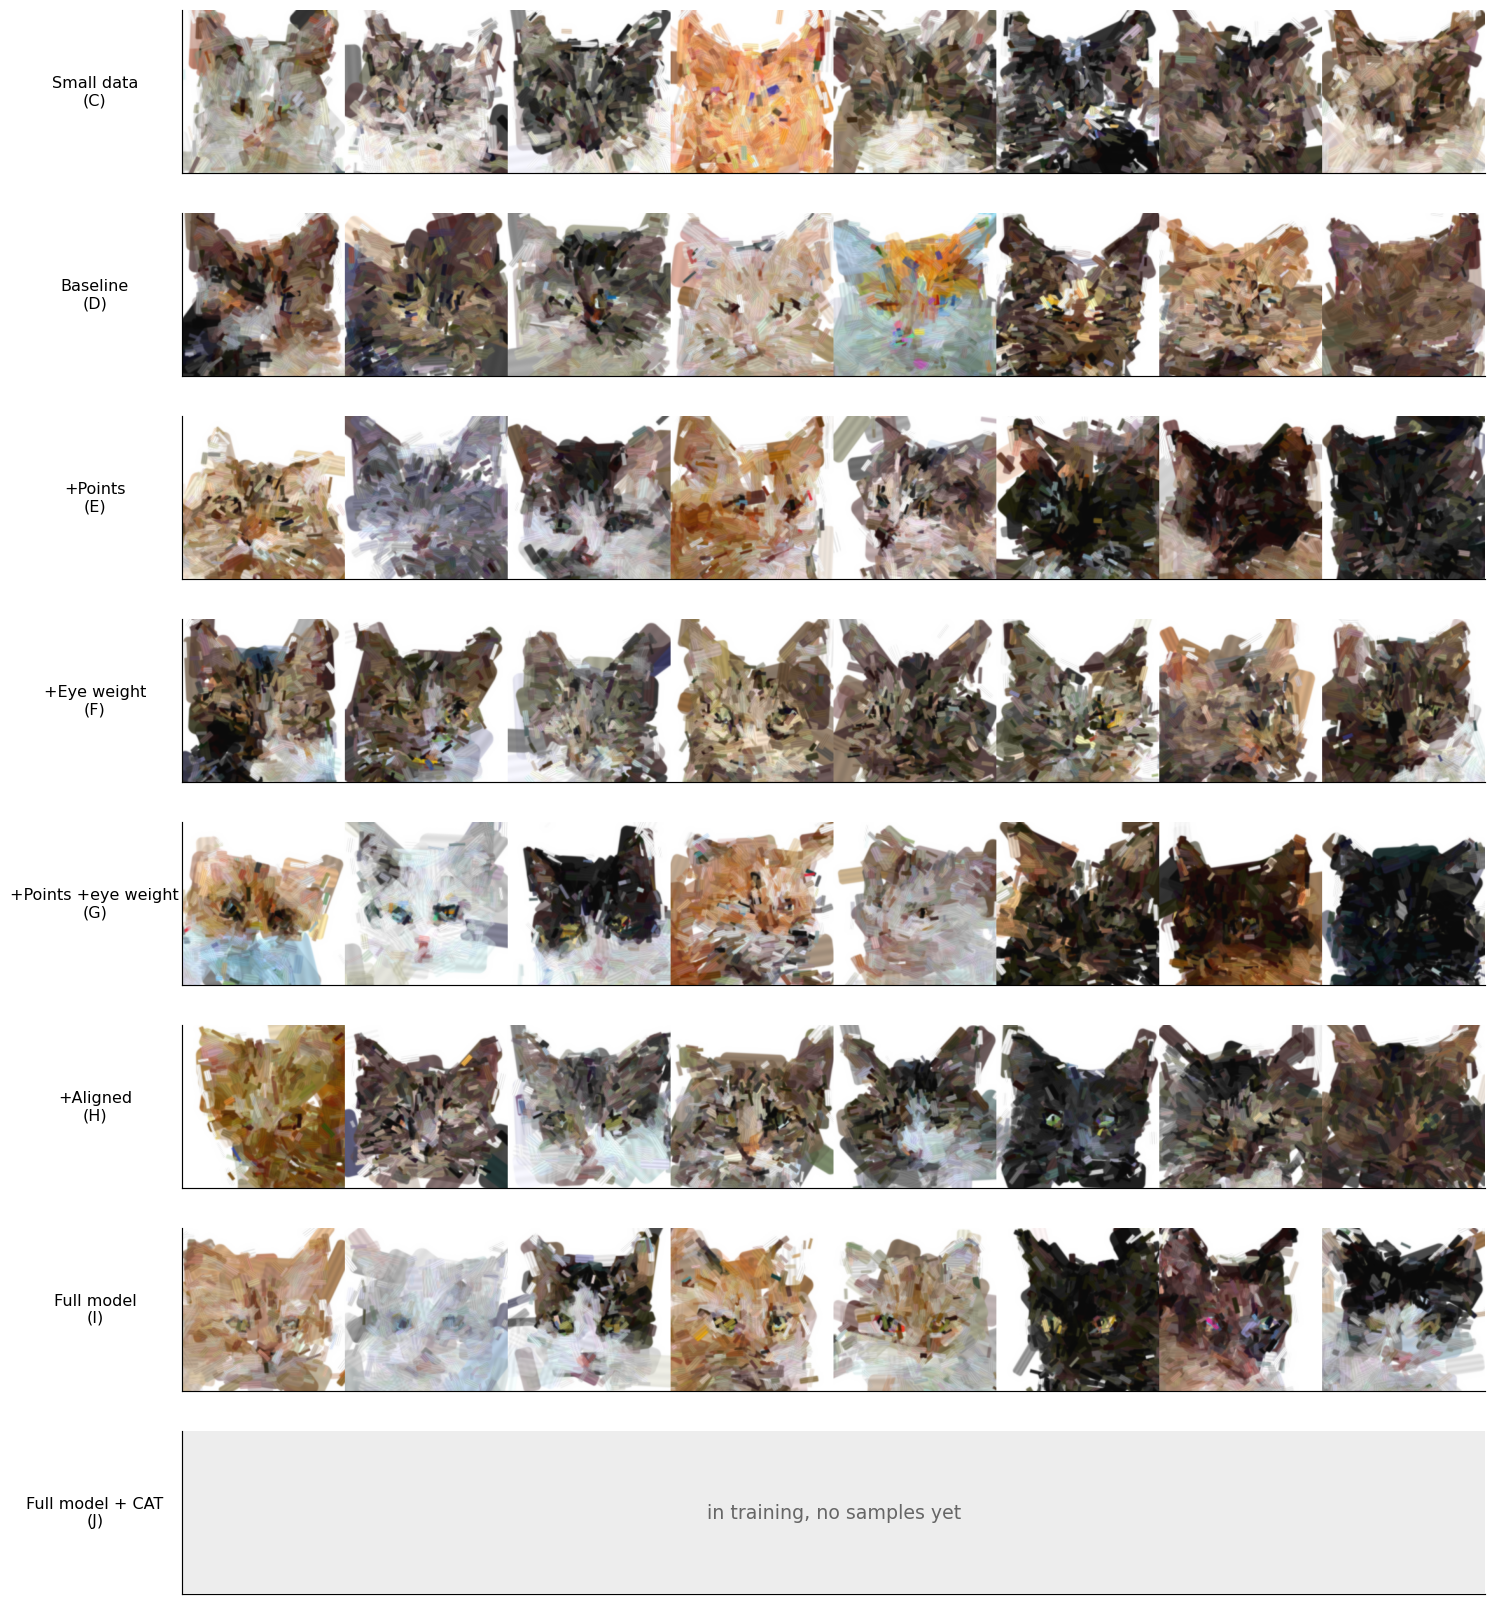

versions with samples: ['C', 'D', 'E', 'F', 'G', 'H', 'I'] ; without samples yet: ['J']
CPU sampling: model I_aligned_points_eyes, seed 0, device cpu, 8 cats; 3063 tokens per cat
seconds per cat on the CPU: [12.61, 12.59, 13.21, 12.27, 15.58, 15.51, 16.21, 13.3]  mean 13.9
every token lies in the field its position allows: True


(13.9, 8)

In [2]:
sh = np.load(need(Path("_src/data_08/samples_run_I_cpu.npz")))
rows_sh = sh["tokens"]
secs = sh["seconds"]
se_ = json.loads(need(Path("_src/data_08/samples_run_I_cpu_eye.json")).read_text())


def first_n_strokes(stages, n):
    '''The first n strokes in painting order (what is on the canvas after n strokes).'''
    out, left = [], n
    for st in stages:
        take = min(left, len(st["alpha"]))
        if take:
            out.append({k: v[:take] for k, v in st.items()})
        left -= take
        if left <= 0:
            break
    return out


def render_n(row, n):
    if n == 0:
        return np.ones((B.SIDE, B.SIDE, 3))
    return T.render(first_n_strokes(T.decode(G.strokes_only(row).tolist()), n)).clip(0, 1)


FIG1 = NAMES + ["J_cat_aligned_points_eyes"]          # training order; new versions are appended
LABEL_ALL = {**LABEL, "J_cat_aligned_points_eyes": "Full model + CAT"}
fig, ax = plt.subplots(len(FIG1), 1, figsize=(14, 1.95 * len(FIG1)))
for a, n in zip(ax, FIG1):
    f_ = RUNS / n / "samples.png"
    if f_.exists():
        a.imshow(Image.open(need(f_)).convert("RGB").crop((0, 0, 2048, 256)))     # first row = first 8 samples
    else:
        a.imshow(np.full((256, 2048, 3), 0.93))
        a.text(1024, 128, "in training, no samples yet", ha="center", va="center", fontsize=13, color="0.4")
    a.set_xticks([])
    a.set_yticks([])
    a.grid(False)
    a.set_ylabel(f"{LABEL_ALL[n]}\n({n[0]})", rotation=0, labelpad=60, fontsize=11, va="center")
plt.tight_layout()
plt.show()
print("versions with samples:", [n[0] for n in FIG1 if (RUNS / n / "samples.png").exists()],
      "; without samples yet:", [n[0] for n in FIG1 if not (RUNS / n / "samples.png").exists()])
print(f"CPU sampling: model {sh['run']}, seed {int(sh['seed'])}, device {sh['device']}, {len(rows_sh)} cats; "
      f"{rows_sh.shape[1] - 1} tokens per cat")
print("seconds per cat on the CPU:", secs.tolist(), " mean", round(float(secs.mean()), 1))
print("every token lies in the field its position allows:", bool(G.valid(rows_sh).all()))
ver("Full model, 8 cats sampled on the CPU: mean seconds per cat / cats", (round(float(secs.mean()), 1), len(secs)),
    "_src/data_08/samples_run_I_cpu.npz", "computed here")

**Figure 1.** Unconditional samples from each version of Brush GPT (eight per row, temperature 1, seed 0, not
selected), from top to bottom in training order: from Small data (C) to the Full model (I). The last row is reserved
for the Full model + CAT (J), which is still in training. The same seed means the same stream of random numbers, not
the same cat: the versions differ, so each row shows different cats. Section 6.1 compares the versions
quantitatively.

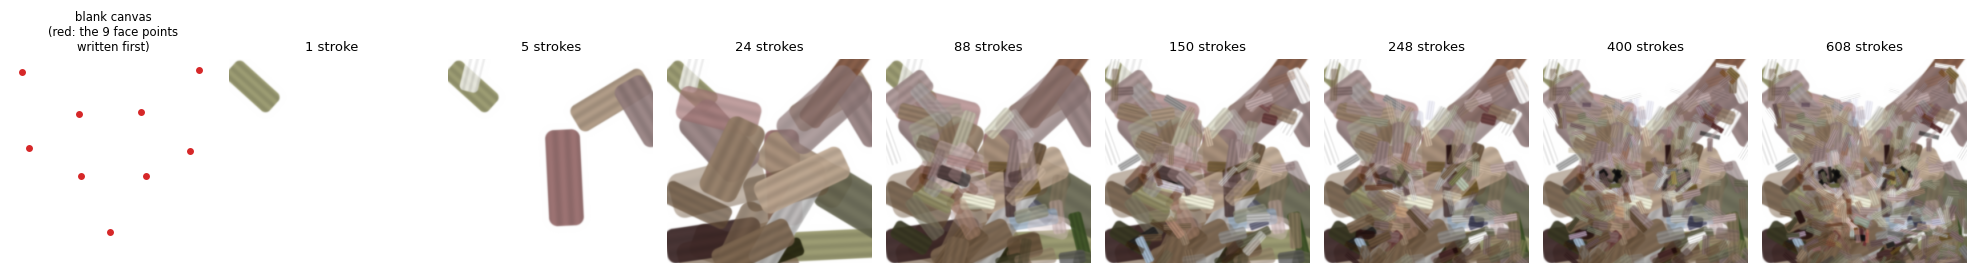

In [3]:
counts = [0, 1, 5, 24, 88, 150, 248, 400, 608]            # 24, 88, 248 and 608 end stages 1-4
cat = 3
pts = (rows_sh[cat, 1:1 + G.PREFIX].reshape(-1, 2) - np.array([T.OFFSET["x"], T.OFFSET["y"]]) + 0.5)
fig, ax = plt.subplots(1, len(counts), figsize=(2.1 * len(counts), 2.5))
for a, n in zip(ax, counts):
    a.imshow(render_n(rows_sh[cat], n))
    a.set_title(f"{n} stroke{'' if n == 1 else 's'}", fontsize=9)
    a.axis("off")
ax[0].scatter(pts[:, 0], pts[:, 1], c="tab:red", s=14)
ax[0].set_title("blank canvas\n(red: the 9 face points\nwritten first)", fontsize=8)
plt.tight_layout()
plt.show()

**Figure 2.** How one cat is painted: a sample drawn by the Full model (I) on a laptop CPU with seed 0, re-rendered
from its tokens after 0, 1, 5, 24, 88, 150, 248, 400 and 608 strokes. The model first writes the nine face points
(red dots, Section 4.5) and then starts painting. The first 24 strokes are broad blocks of colour (stage 1), strokes
25–88 shape the head and ears (stage 2), strokes 89–248 are where the eyes, nose and stripes usually first appear
(stage 3), and the last 360 strokes add detail (stage 4). A stroke, once laid down, is never changed; it can only be
covered by later strokes.

## 2. Related work

This section groups the work whose titles come closest to this paper into five lines of research. For each, I first
state the problem it solves in a sentence or two, then set it **side by side** with this paper in a table, and finally
explain why it cannot replace the work presented here. The column for this paper refers to the sections where each
entry is described; the other columns are taken from the cited papers themselves.

### 2.1 Reconstructing a given image with strokes (stroke-based rendering)

Methods in this line take a **target image** as input and output a set of strokes that paints it: the question they
answer is how to reproduce a given picture with strokes.

**Table 1a.** Stroke-based reconstruction methods compared with this paper.

| | **This paper (Brush GPT)** | Learning to Paint [1] | SNP [2] | Paint Transformer [3] | Intelli-Paint [4] | AttentionPainter and others [5–7] |
|---|---|---|---|---|---|---|
| Input | **None** (blank canvas) | Target image | Target image | Target image | Target image | Target image |
| Can paint a cat absent from the training data | **Yes** | No (reproduces the given image only) | No | No | No | No |
| What is learned | The distribution of stroke sequences (a generative model) | A policy that decomposes an image into strokes | Nothing; each image is optimised separately | An image-to-strokes mapping | An image-to-strokes mapping with a human-like order | Image to strokes, with better efficiency, texture or ordering |
| Who decides each stroke | The model, sampling token by token | An agent, guided by the target image | Gradient descent towards the target image | A network, from the target image | From the target image | From the target image |

**Difference.** This line answers how to reproduce a picture that already exists; this paper asks how to paint a cat
when there is no picture at all. Because the inputs differ, these methods cannot perform the task studied here. I use
this kind of technique only to **build the training data**: the painter of Section 4.1 optimises strokes directly
through a differentiable renderer (the approach of SNP) to turn training photographs into stroke sequences. It is
data preprocessing, not the generative model this paper evaluates.

### 2.2 Generating stroke sequences without a target image

This line is the closest to this paper: the model produces strokes itself instead of reproducing a given picture.

**Table 1b.** Stroke-sequence generation methods compared with this paper.

| | **This paper (Brush GPT)** | Sketch-RNN [8] | Sketchformer [9] | I-Paint [10] | PaintCopilot [11] |
|---|---|---|---|---|---|
| Needs a reference image or the current canvas | **No** | No | No | Reference photo and current canvas | Current canvas, pulled towards a target image |
| Output | **Coloured, overlapping oil-paint strokes** | Black-and-white line sketches | Black-and-white lines (a representation for classification and retrieval) | Oil-paint strokes | Strokes |
| Brush size | **Yes** (each stroke also has an opacity) | No | No | Yes | Yes |
| Coarse-to-fine stages | **4 stages, always 608 strokes** | No | No | No | No |
| Composition decided before painting | **9 face points written first** | No | No | No | Predicts a target image |
| Evaluation of structural correctness | **Independent landmark judge (eyes); errors located by stage** | Log-likelihood | Classification and retrieval accuracy | FSD, human evaluation | Behavioural checks, use by artists |

**Difference.** The only methods that paint without any reference, Sketch-RNN and Sketchformer, produce
black-and-white lines with no colour, brush or overlap. The methods with colour and brushes, I-Paint and PaintCopilot,
both need a reference photo or the current canvas. **Only this paper does both: it needs no reference of any kind and
produces coloured, overlapping oil-paint strokes.** I-Paint also reorders strokes when building its data (consecutive
strokes kept close, overlapping strokes kept in their original order), a concept close to the overlap order of
Section 4.3. The two were proposed independently and pursue different goals (I-Paint seeks continuity, this paper
top-to-bottom bands), and neither compares how stroke order affects **learnability**.

### 2.3 Autoregressive generation of vector graphics from discrete tokens

This line is the closest to this paper in **representation**: graphics are discretised into tokens and a Transformer
generates them one token at a time.

**Table 1c.** Token-based vector-graphics generation compared with this paper.

| | **This paper (Brush GPT)** | IconShop [12] | StrokeNUWA [13] |
|---|---|---|---|
| What is generated | **Oil-painted cat faces** | Black-and-white vector icons | Black-and-white vector icons |
| Colour, brush size, overlap | **Yes** | No | No |
| Condition | **None** | Text (optional) | Text (required) |
| Tokens per stroke | **Always 5, each a readable field** (position, angle, size, colour) | Path commands and coordinates | Codes learned by vector quantisation (not directly readable) |
| Coarse-to-fine stages | **4 stages** | No | No |
| Model size | **27.9 million parameters; about 14 s per cat on a laptop CPU** | 12-layer decoder | 3 billion parameters (Flan-T5) |
| Evaluation | **Independent landmark judge (structure), FID, KID, diversity** | FID, Uniqueness / Novelty | FID, CLIPScore |

**Difference.** Representing graphics as discrete tokens generated autoregressively has already been done, and done
well, for vector icons (IconShop reaches an FID of 6.08 in unconditional generation); I do not claim it as new. Icons,
however, are single-colour lines without brushes or overlap. Every oil-paint stroke also carries a colour, a size and
an opacity, and later strokes cover earlier ones, so the sequences are longer (3,064 tokens), the fields differ more in
nature, and stroke order directly determines the picture (Section 1.2). These are exactly the problems that icons do
not pose and that this paper addresses.

### 2.4 Generating the painting process as pixel video

This line also generates the process from a blank canvas to a finished picture, but its output is pixel frames.

**Table 1d.** Painting-process video generation compared with this paper.

| | **This paper (Brush GPT)** | ProcessPainter [14] | PaintsAlter [15] | Inverse Painting [16] | Loomis Painter [17] |
|---|---|---|---|---|---|
| Required input | **None** | Text | A canvas | A finished painting | An image |
| Output | **Stroke parameters (each stroke can be edited or removed on its own)** | 8 pixel frames | Earlier or later pixel canvases | A pixel time-lapse | A pixel video |
| Granularity of the process | **608 strokes** | 8 frames | — | One semantic region at a time | Video frames |
| Model and compute | **27.9 million parameters; 8–16 minutes of training on one A100** | Stable Diffusion + AnimateDiff | Video diffusion model; 4–9 days on 8 H100s | LLaVA + a diffusion model | 14-billion-parameter video model; 24 hours on 4 H100s |

**Difference.** Video models produce pixels that look like painting in progress, but there is no stroke in them that
can be taken out and changed. The output of this paper is the strokes themselves, so the process can be replayed,
and each stroke edited or removed, one at a time; this is also what makes the local repainting of Section 11
possible. The model is also far smaller, about 500 times smaller than the 14 billion parameters of Loomis Painter.
Two observations from this line are relevant here: Inverse Painting treats the order of painting one semantic region
at a time as something to be learned, and Loomis Painter finds that training on frames in reverse order works better,
showing that **order affects learnability**.

### 2.5 Stroke direction: from image orientation fields to fur flow

Which way a stroke should point has a long history in stroke-based rendering. The painter of Section 4.1 belongs to
the family that takes direction from the image; the oil-process painter of Section 10 instead derives fur flow from
an animal's facial keypoints.

**Table 1e.** Where stroke direction comes from: existing methods and Section 10 of this paper.

| | **This paper, Section 10** | Litwinowicz [32], Hertzmann [33] | Hays and Essa [34], Im2Oil [43] | Wagner et al. [36] | Zhao and Zhu [38], Wang et al. [37] | AutoHair [40], NeuralFur [41] |
|---|---|---|---|---|---|---|
| Source of direction | **Facial keypoints + rules of fur growth** (refined by image texture) | Image gradients | Strong edges (interpolated with radial basis functions, or the edge tangent flow of Kang et al. [53]) | Local image orientation (facial points only decide where detail strokes go) | Facial landmarks + contours and image edges | Learned growth direction of hair or fur |
| Subject | **Animal (cat) faces** | Any photograph | Any photograph | Portraits | Portraits | Human hair; animal bodies |
| Purpose | **2D stroke-based painting** | 2D stroke-based painting | 2D stroke-based painting | 2D stroke-based painting | 2D stroke-based painting | 3D reconstruction |
| Follows the direction of fur growth | **Yes** | No (follows edges) | No (follows edges) | No | No (follows contours) | Yes, but not used to place strokes |

**Difference.** In stroke-based painting, direction comes either from image edges or from the contours of human faces;
the methods that model the growth direction of hair and fur do so for 3D reconstruction, not for painting strokes.
**Chaining animal facial keypoints to a fur-growth direction and then to the direction of every stroke has no
precedent in the literature I found** (Section 10.3). I do not claim that shaping an orientation field with facial
points, or modelling the growth direction of hair, is new in itself. Section 10.4 also measures that the three
image-only rules from the literature are almost unrelated to the direction of fur growth (42.5–46.3° away from it,
indistinguishable from the 45° of random directions). Other related approaches, in which Salisbury et al. [42] draw
an orientation field by hand on the photograph, Kotovenko et al. [54] let the user steer the flow of strokes with
drawn curves, and Kowalski et al. [35] suggest fur with a few tufts on a 3D model, all require a person to specify the
direction. Appendix F gives the details of each paper.

### 2.6 Positioning of this paper

**Table 1.** Comparison with the three closest works.

| | This paper | I-Paint [10] | IconShop [12] | PaintCopilot [11] |
|---|---|---|---|---|
| Condition | **None** | Reference photo + current canvas | Text (optional) | Current canvas + target image |
| Output | Coloured, overlapping oil-paint strokes | Oil-paint strokes | Black-and-white vector paths | Strokes |
| Representation of a stroke | 5 discrete tokens | 8 continuous values | Discrete coordinate tokens | 8 continuous values |
| Generation | Autoregressive (token by token) | Conditional VAE (8 strokes at a time) | Autoregressive | Autoregressive + flow matching |
| Coarse to fine | 4 stages, 608 strokes | — | — | — |
| Compositional plan | 9 face points written first | None | None | Predicts a target image |
| Structural evaluation | Independent landmark judge (eyes) | FSD, human evaluation | FID, Uniqueness / Novelty | Behavioural checks, use by artists |

This paper differs from them in two ways. First, it generates coloured, overlapping, coarse-to-fine oil-paint strokes
**fully unconditionally** and autoregressively, opening each sequence with a compositional plan. Second, its evaluation
does not stop at the distribution distance of whole images: an independent judge measures **structure**, and errors
are **located by stage**.

## References

1. Z. Huang, W. Heng, S. Zhou. Learning to Paint with Model-based Deep Reinforcement Learning. *ICCV*, 2019.
2. Z. Zou, T. Shi, S. Qiu, Y. Yuan, Z. Shi. Stylized Neural Painting. *CVPR*, 2021.
3. S. Liu et al. Paint Transformer: Feed Forward Neural Painting with Stroke Prediction. *ICCV*, 2021.
4. J. Singh, C. Smith, J. Echevarria, L. Zheng. Intelli-Paint: Towards Developing More Human-Intelligible Painting Agents. *ECCV*, 2022.
5. Y. Tang et al. AttentionPainter: An Efficient and Adaptive Stroke Predictor for Scene Painting. arXiv:2410.16418, 2024.
6. Y. Jiang et al. Birth of a Painting: Differentiable Brushstroke Reconstruction. arXiv:2511.13191, 2025.
7. Y. Qin et al. Data-Efficient Brushstroke Generation with Diffusion Models for Oil Painting. arXiv:2603.01103, 2026.
8. D. Ha, D. Eck. A Neural Representation of Sketch Drawings. *ICLR*, 2018.
9. L. S. F. Ribeiro, T. Bui, J. Collomosse, M. Ponti. Sketchformer: Transformer-based Representation for Sketched Structure. *CVPR*, 2020.
10. E. Peruzzo et al. Interactive Neural Painting. *Computer Vision and Image Understanding*, 2023. arXiv:2307.16441.
11. Wen et al. PaintCopilot: Modeling Painting as Autonomous Artistic Continuation. arXiv:2605.20941, 2026.
12. R. Wu, W. Su, K. Ma, J. Liao. IconShop: Text-Guided Vector Icon Synthesis with Autoregressive Transformers. *ACM TOG (SIGGRAPH Asia)*, 2023.
13. Z. Tang et al. StrokeNUWA: Tokenizing Strokes for Vector Graphic Synthesis. *ICML*, 2024.
14. Y. Song et al. ProcessPainter: Learn Painting Process from Sequence Data. arXiv:2406.06062, 2024.
15. L. Zhang, C. Yan, Y. Guo, J. Xing, M. Agrawala. Generating Past and Future in Digital Painting Processes. *ACM TOG* 44(4), 2025.
16. B. Chen et al. Inverse Painting: Reconstructing the Painting Process. *SIGGRAPH Asia*, 2024.
17. M. Pobitzer et al. Loomis Painter: Reconstructing the Painting Process. arXiv:2511.17344, 2025.
18. Y. Choi, Y. Uh, J. Yoo, J.-W. Ha. StarGAN v2: Diverse Image Synthesis for Multiple Domains. *CVPR*, 2020. (AFHQ dataset)
19. W. Zhang, J. Sun, X. Tang. Cat Head Detection – How to Effectively Exploit Shape and Texture Features. *ECCV*, 2008. (CAT dataset)
20. K. He, X. Chen, S. Xie, Y. Li, P. Dollár, R. Girshick. Masked Autoencoders Are Scalable Vision Learners. *CVPR*, 2022.
21. Y. Xu, J. Zhang, Q. Zhang, D. Tao. ViTPose: Simple Vision Transformer Baselines for Human Pose Estimation. *NeurIPS*, 2022.
22. A. Radford, J. Wu, R. Child, D. Luan, D. Amodei, I. Sutskever. Language Models are Unsupervised Multitask Learners. OpenAI, 2019.
23. H. Touvron et al. LLaMA: Open and Efficient Foundation Language Models. arXiv:2302.13971, 2023.
24. J. Su, Y. Lu, S. Pan, A. Murtadha, B. Wen, Y. Liu. RoFormer: Enhanced Transformer with Rotary Position Embedding. arXiv:2104.09864, 2021.
25. N. Shazeer. GLU Variants Improve Transformer. arXiv:2002.05202, 2020.
26. B. Zhang, R. Sennrich. Root Mean Square Layer Normalization. *NeurIPS*, 2019.
27. I. Loshchilov, F. Hutter. Decoupled Weight Decay Regularization. *ICLR*, 2019.
28. M. Heusel, H. Ramsauer, T. Unterthiner, B. Nessler, S. Hochreiter. GANs Trained by a Two Time-Scale Update Rule Converge to a Local Nash Equilibrium. *NeurIPS*, 2017.
29. M. Bińkowski, D. J. Sutherland, M. Arbel, A. Gretton. Demystifying MMD GANs. *ICLR*, 2018.
30. A. Radford et al. Learning Transferable Visual Models From Natural Language Supervision. *ICML*, 2021.
31. X. Xu, K. D. D. Willis, J. G. Lambourne, C.-Y. Cheng, P. K. Jayaraman, Y. Furukawa. SkexGen: Autoregressive Generation of CAD Construction Sequences with Disentangled Codebooks. *ICML*, 2022.
32. P. Litwinowicz. Processing Images and Video for an Impressionist Effect. *SIGGRAPH*, 1997.
33. A. Hertzmann. Painterly Rendering with Curved Brush Strokes of Multiple Sizes. *SIGGRAPH*, 1998.
34. J. Hays, I. Essa. Image and Video Based Painterly Animation. *NPAR*, 2004.
35. M. A. Kowalski, L. Markosian, J. D. Northrup, L. Bourdev, R. Barzel, L. S. Holden, J. F. Hughes. Art-Based Rendering of Fur, Grass, and Trees. *SIGGRAPH*, 1999.
36. R. Wagner, S. Schulz, M. Reimann, A. Semmo, J. Döllner, M. Trapp. Art-directable Stroke-based Rendering on Mobile Devices. *VMV*, pp. 173–180, 2023.
37. T. Wang, J. Collomosse, A. Hunter, D. Greig. Learnable Stroke Models for Example-based Portrait Painting. *BMVC*, 2013.
38. M. Zhao, S.-C. Zhu. Portrait Painting Using Active Templates. *NPAR*, pp. 117–124, 2011.
39. K. Zeng, M. Zhao, C. Xiong, S.-C. Zhu. From Image Parsing to Painterly Rendering. *ACM TOG* 29(1), 2009.
40. M. Chai, T. Shao, H. Wu, Y. Weng, K. Zhou. AutoHair: Fully Automatic Hair Modeling from a Single Image. *ACM TOG* 35(4), 2016.
41. V. Sklyarova, B. Kabadayi, A. Yiannakidis, G. Becherini, M. J. Black, J. Thies. NeuralFur: Animal Fur Reconstruction From Multi-View Images. arXiv:2601.12481, 2026.
42. M. P. Salisbury, M. T. Wong, J. F. Hughes, D. H. Salesin. Orientable Textures for Image-Based Pen-and-Ink Illustration. *SIGGRAPH*, 1997.
43. Z. Tong, X. Wang, S. Yuan, X. Chen, J. Wang, X. Fang. Im2Oil: Stroke-Based Oil Painting Rendering with Linearly Controllable Fineness via Adaptive Sampling. *ACM MM*, 2022.
44. Y. Tang, Y. Wang, et al. AttentionPainter: An Efficient and Adaptive Stroke Predictor for Scene Painting. *IEEE TVCG*, 2025（arXiv:2410.16418）.
45. J. Singh, L. Zheng. Combining Semantic Guidance and Deep Reinforcement Learning for Generating Human Level Paintings. *CVPR*, 2021.
46. J. P. Collomosse, P. M. Hall. Painterly Rendering using Image Salience. *Eurographics UK*, pp. 122–128, 2002.
47. D. Neulander. Painterly Picture Generation. US Patent 9,767,582 B2, 2017.
48. R. Yi, Y.-J. Liu, Y.-K. Lai, P. L. Rosin. APDrawingGAN: Generating Artistic Portrait Drawings from Face Photos with Hierarchical GANs. *CVPR*, 2019.
49. A. Santella, D. DeCarlo. Abstracted Painterly Renderings Using Eye-Tracking Data. *NPAR*, 2002.
50. T. Lindemeier, M. Spicker, O. Deussen. Artistic Composition for Painterly Rendering. *VMV*, 2016.
51. Z. Hu, Y. Chen, J. Yao, B. Ni. PaintFlow: A Unified Framework for Interactive Oil Paintings Editing and Generation. arXiv:2512.08534, 2025.
52. J. E. Kyprianidis, J. Döllner. Image Abstraction by Structure Adaptive Filtering. *EG UK Theory and Practice of Computer Graphics*, pp. 51–58, 2008.
53. H. Kang, S. Lee, C. K. Chui. Coherent Line Drawing. *NPAR*, pp. 43–50, 2007.
54. D. Kotovenko, M. Wright, A. Heimbrecht, B. Ommer. Rethinking Style Transfer: From Pixels to Parameterized Brushstrokes. *CVPR*, 2021.
55. D. DeCarlo, A. Santella. Stylization and Abstraction of Photographs. *ACM TOG* 21(3)（SIGGRAPH）, pp. 769–776, 2002.
56. T. Hu, R. Yi, H. Zhu, L. Liu, J. Peng, Y. Wang, C. Wang, L. Ma. Stroke-based Neural Painting and Stylization with Dynamically Predicted Painting Region（Compositional Neural Painter）. *ACM MM*, 2023.
57. R. Nakano. Neural Painters: A Learned Differentiable Constraint for Generating Brushstroke Paintings. arXiv:1904.08410, 2019（NeurIPS Workshop on Machine Learning for Creativity and Design）.
58. L. Liu, Y. Wang, L. Zhu, L. Liao, Z. Zheng. Look, Compare and Draw: Differential Query Transformer for Automatic Oil Painting. arXiv:2603.27720, 2026.
59. J. Ho, T. Salimans. Classifier-Free Diffusion Guidance. arXiv:2207.12598, 2022.